# Chapitre 9 - Cours 4 : Optimiser le service d'inférence

Les optimisations du service ne touchent pas au modèle : elles décident **quand** et
**où** exécuter chaque requête, avec des ressources fixes (calcul, mémoire) face à une
charge variable. Elles ne doivent donc pas changer les sorties. Ce notebook couvre la
section *Inference Service Optimization* du livre :

- *Batching* : statique, dynamique, continu ;
- *Decoupling prefill and decode* ;
- *Prompt caching* ;
- *Parallelism* : répliques, parallélisme de tenseur, de pipeline, de contexte et de
  séquence.

Pour le batching, nous **mesurons** d'abord le coût d'un pas sur le GPU, puis nous
l'injectons dans une **simulation à événements discrets** d'un serveur : on peut ainsi
comparer les politiques sur des milliers de requêtes en quelques secondes.

**Plan.** 1. Le service comme une file d'attente ; 2. Calibrer un modèle de coût ;
3. Batching statique, dynamique et continu ; 4. Dissocier prefill et decode ; 5. Cache de
prompt ; 6. Parallélisme ; Synthèse.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie import llm
from aie import ch09_inference as inf
from aie.ch02_modeles import KNOWN_CONFIGS, count_params_config, kv_cache_bytes, plain_log_axis
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT, COLORS,
                          annotate_bars, subtitle, finish)

set_style()
warnings.filterwarnings("ignore")
llm.seed_everything(0)
rng = np.random.default_rng(0)
pd.set_option("display.precision", 3)
POL = {"none": ("sans batching", GRAY), "static": ("statique", ROSE), "dynamic": ("dynamique", AMBER),
       "continuous": ("continu", TEAL)}

## 1. Le service comme une file d'attente (section *Inference Service Optimization*)

Vu de loin, un serveur d'inférence est une **file d'attente** : les requêtes arrivent à des
instants aléatoires, attendent, sont regroupées en lots par un **ordonnanceur**, puis
exécutées sur le GPU. Le livre compare le batching au **bus** : un bus transporte plus de
monde qu'une voiture par personne, mais chacun attend son départ. Toute la question est de
faire partir le bus au bon moment.

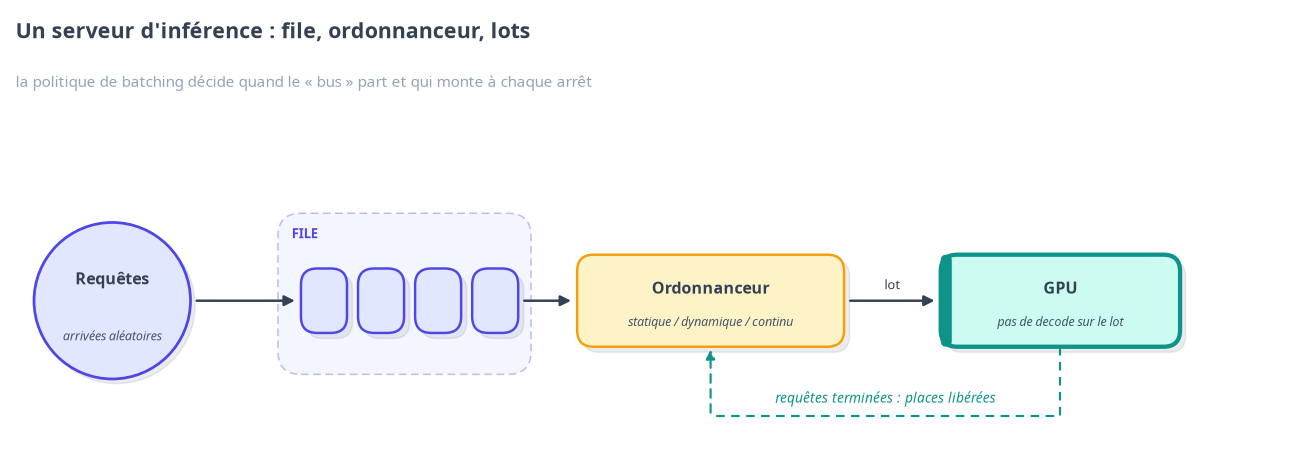

In [2]:
d = Diagram(14, 3.8, title="Un serveur d'inférence : file, ordonnanceur, lots",
            subtitle="la politique de batching décide quand le « bus » part et qui monte à chaque arrêt")
d.box("arr", 1.1, 1.6, "Requêtes", sub="arrivées aléatoires", color=INDIGO, kind="user", w=1.7)
for i in range(4):
    d.box(f"q{i}", 3.4 + i * 0.62, 1.6, "", color=INDIGO, w=0.5, h=0.7)
d.group(2.9, 0.8, 5.65, 2.55, "file", color=INDIGO)
d.box("sch", 7.6, 1.6, "Ordonnanceur", sub="statique / dynamique / continu", color=AMBER, w=2.9, h=1.0)
d.box("gpu", 11.4, 1.6, "GPU", sub="pas de decode sur le lot", color=TEAL, kind="model", w=2.6, h=1.0)
d.arrow("arr", "q0"); d.arrow("q3", "sch"); d.arrow("sch", "gpu", "lot")
d.line([(11.4, 1.1), (11.4, 0.35), (7.6, 0.35), (7.6, 1.1)], color=TEAL, style="dashed", lw=1.4)
d.note(9.5, 0.55, "requêtes terminées : places libérées", color=TEAL, fontsize=9)
d.show()

> **À retenir.** Le service gère des ressources fixes face à une charge variable ; ses
> techniques jouent sur l'ordonnancement, l'emplacement et la réutilisation des calculs,
> sans modifier le modèle.

## 2. Calibrer un modèle de coût (mesures sur le GPU)

Pour simuler un serveur, il faut savoir combien coûte un pas de calcul. Les cours 1 et 2
suggèrent un modèle linéaire :
$$t_{\text{decode}}(b) = a_0 + a_1 b, \qquad t_{\text{prefill}}(n) = p_0 + p_1 n,$$
avec $b$ le nombre de séquences décodées ensemble et $n$ le nombre de tokens préremplis.
On mesure ces durées sur Qwen2.5-0.5B (médianes de répétitions) et on ajuste les
coefficients par moindres carrés.

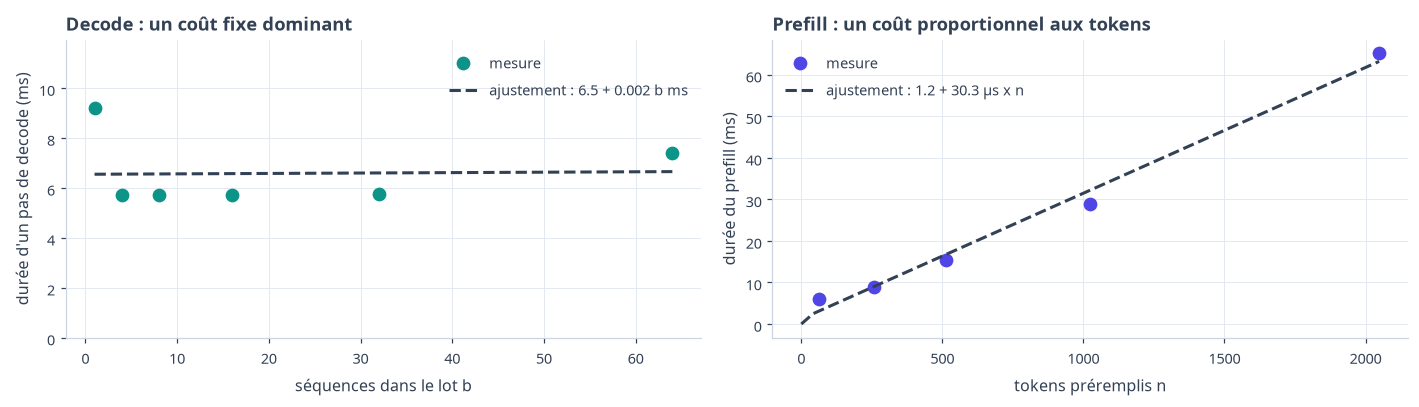

In [3]:
tok, model = inf.retry_oom(llm.load, llm.SMALL)


def calibrate():
    dec = [(b, inf.decode_step_time(model, batch=b, context=256, steps=16)["median"]) for b in [1, 4, 8, 16, 32, 64]]
    pre = [(n, inf.prefill_time(model, n, repeats=5)["median"]) for n in [64, 256, 512, 1024, 2048]]
    return np.array(dec), np.array(pre)


dec, pre = inf.retry_oom(calibrate)
a1, a0 = np.polyfit(dec[:, 0], dec[:, 1], 1)
p1, p0 = np.polyfit(pre[:, 0], pre[:, 1], 1)
cost = inf.StepCost(dec0=max(a0, 1e-3), dec1=max(a1, 1e-6), pre0=max(p0, 1e-3), pre1=max(p1, 1e-7))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
ax.plot(dec[:, 0], dec[:, 1] * 1e3, "o", color=TEAL, ms=8, label="mesure")
bb = np.linspace(1, 64, 50)
ax.plot(bb, [cost.decode(b) * 1e3 for b in bb], color=SLATE, ls="--",
        label=f"ajustement : {cost.dec0 * 1e3:.1f} + {cost.dec1 * 1e3:.3f} b ms")
ax.set_xlabel("séquences dans le lot b"); ax.set_ylabel("durée d'un pas de decode (ms)"); ax.legend()
ax.set_ylim(0, dec[:, 1].max() * 1e3 * 1.3); ax.set_title("Decode : un coût fixe dominant")
ax = axes[1]
ax.plot(pre[:, 0], pre[:, 1] * 1e3, "o", color=INDIGO, ms=8, label="mesure")
nn = np.linspace(0, 2048, 50)
ax.plot(nn, [cost.prefill(n) * 1e3 for n in nn], color=SLATE, ls="--",
        label=f"ajustement : {cost.pre0 * 1e3:.1f} + {cost.pre1 * 1e6:.1f} µs x n")
ax.set_xlabel("tokens préremplis n"); ax.set_ylabel("durée du prefill (ms)"); ax.legend()
ax.set_title("Prefill : un coût proportionnel aux tokens")
plt.tight_layout(); plt.show()

Le modèle linéaire décrit bien les mesures. Le terme fixe du decode $a_0$ (lecture des
poids et surcoût de lancement) domine le terme par séquence $a_1$ de plus d'un ordre de
grandeur : c'est ce rapport qui rend le batching si rentable. Ces coefficients
alimentent toutes les simulations de la suite.

> **À retenir.** Un pas de decode coûte $a_0 + a_1 b$ avec $a_0 \gg a_1$ : servir $b$
> séquences coûte à peine plus qu'en servir une.

## 3. Batching statique, dynamique et continu (section *Batching*)

- **Statique** : le bus attend d'être plein (taille de lot fixe $B$). La première requête
  attend la $B$-ième, aussi tard soit-elle.
- **Dynamique** : le bus part quand il est plein **ou** après une fenêtre de temps fixe
  (par exemple 100 ms) ; la latence est bornée, au prix de lots parfois incomplets.
- **Continu** (*continuous* ou *in-flight batching*, Orca, Yu et al., 2022) : le lot est
  recomposé à **chaque pas** de decode ; une requête terminée sort immédiatement et une
  requête en attente prend sa place. Le bus dépose et prend des passagers à chaque arrêt.

Dans un batching naïf (statique ou dynamique), une réponse de 10 tokens attend la fin d'une
réponse de 1 000 tokens du même lot. Visualisons les trois politiques sur 12 requêtes
(arrivées de Poisson, longueurs de sortie très variables), avec des lots de 4.

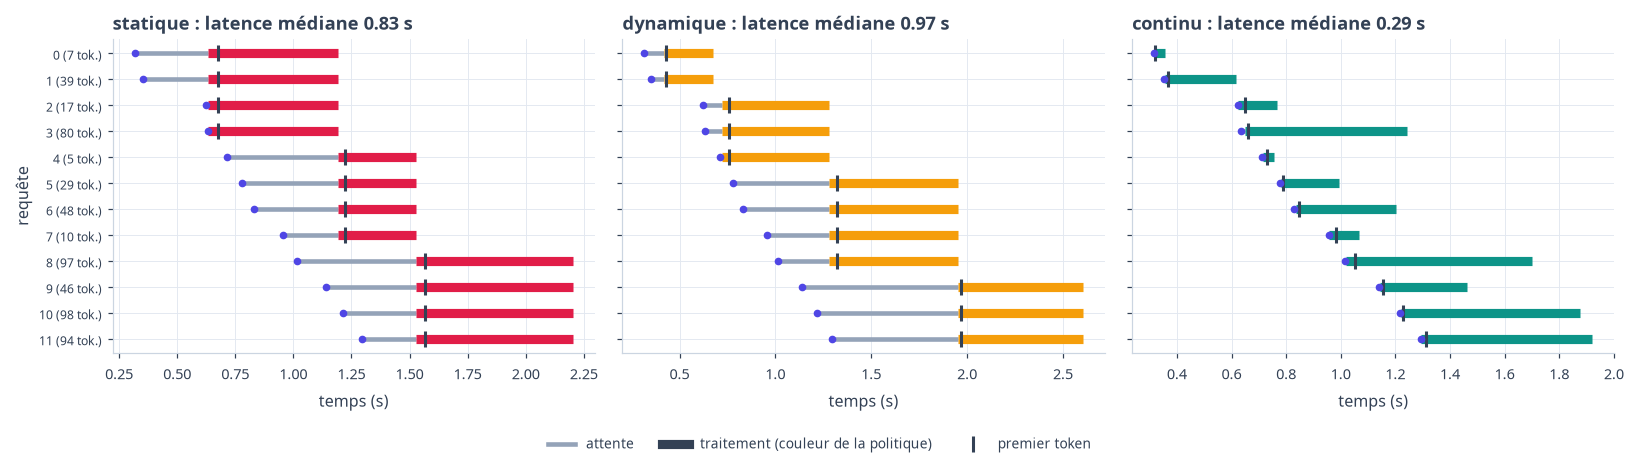

In [4]:
w12 = inf.make_workload(12, rate=12, seed=4, out_median=40, out_sigma=0.9)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, pol in zip(axes, ["static", "dynamic", "continuous"]):
    res = inf.simulate_batching(w12, pol, max_batch=4, window=0.1, cost=cost)
    name, c = POL[pol]
    for i, r in res.iterrows():
        ax.plot([r.arrivee, r.debut], [i, i], color=GRAY, lw=3, solid_capstyle="butt")
        ax.plot([r.debut, r.fin], [i, i], color=c, lw=6, solid_capstyle="butt")
        ax.plot(r.premier_token, i, "|", color=SLATE, ms=10, mew=2)
        ax.plot(r.arrivee, i, "o", color=INDIGO, ms=4)
    ax.set_title(f"{name} : latence médiane {res['latence'].median():.2f} s")
    ax.set_xlabel("temps (s)"); ax.invert_yaxis() if pol == "static" else None
axes[0].set_ylabel("requête")
axes[0].set_yticks(range(12), [f"{i} ({o} tok.)" for i, o in enumerate(w12["sortie"])], fontsize=8)
handles = [plt.Line2D([], [], color=GRAY, lw=3, label="attente"), plt.Line2D([], [], color=SLATE, lw=6, label="traitement (couleur de la politique)"),
           plt.Line2D([], [], color=SLATE, marker="|", ls="", ms=10, mew=2, label="premier token")]
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=9, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

En statique, les premières requêtes attendent que le lot se remplisse ; en dynamique, la
fenêtre limite cette attente ; dans les deux cas, les réponses courtes restent bloquées
jusqu'à la fin de la plus longue de leur lot (barres colorées longues pour quelques tokens).
En continu, chaque requête démarre dès qu'une place se libère et sort dès qu'elle a fini.

**Latence contre débit.** On fait maintenant varier le taux d'arrivée (400 requêtes par
point, lots d'au plus 16) et l'on trace la latence médiane et le p90 en fonction du débit
effectivement obtenu.

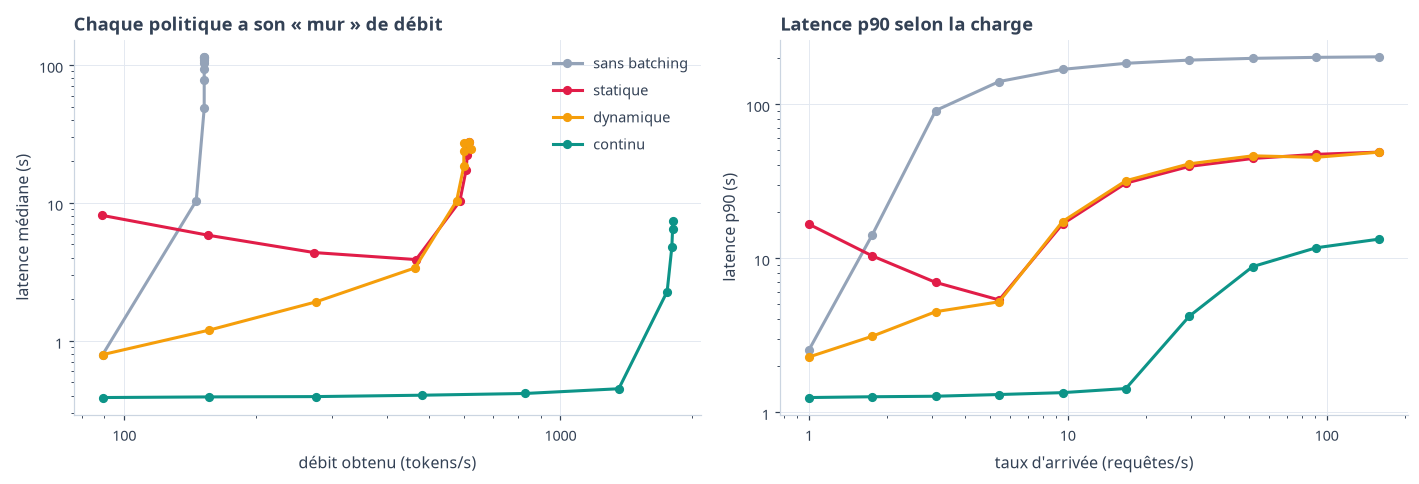

politique,débit (tokens/s)
continu,"1,809"
dynamique,623
sans batching,153
statique,616


In [5]:
rates = np.geomspace(1, 160, 10)
rows = []
for pol in ["none", "static", "dynamic", "continuous"]:
    for lam in rates:
        w = inf.make_workload(400, rate=lam, seed=1)
        res = inf.simulate_batching(w, pol, max_batch=16, window=0.1, cost=cost)
        s = inf.batching_summary(res)
        rows.append(dict(politique=pol, taux=lam, **s))
curves = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for pol, g in curves.groupby("politique", sort=False):
    name, c = POL[pol]
    axes[0].plot(g["débit (tokens/s)"], g["latence p50 (s)"], "o-", color=c, label=name, ms=5)
    axes[1].plot(g["taux"], g["latence p90 (s)"], "o-", color=c, label=name, ms=5)
for ax in axes:
    ax.set_yscale("log"); plain_log_axis(ax, "y")
axes[0].set_xscale("log"); plain_log_axis(axes[0], "x")
axes[0].set_xlabel("débit obtenu (tokens/s)"); axes[0].set_ylabel("latence médiane (s)")
axes[0].set_title("Chaque politique a son « mur » de débit"); axes[0].legend()
axes[1].set_xscale("log"); plain_log_axis(axes[1], "x")
axes[1].set_xlabel("taux d'arrivée (requêtes/s)"); axes[1].set_ylabel("latence p90 (s)")
axes[1].set_title("Latence p90 selon la charge")
plt.tight_layout(); plt.show()
best = curves.loc[curves.groupby("politique")["débit (tokens/s)"].idxmax(), ["politique", "débit (tokens/s)"]]
best.assign(politique=best["politique"].map(lambda p: POL[p][0])).style.format({"débit (tokens/s)": "{:,.0f}"}).hide(axis="index")

Lecture :

- **sans batching**, le serveur sature vite : au-delà de quelques requêtes par seconde, la
  file s'allonge sans fin et la latence explose ;
- le batching **statique** est absurde à faible charge (on attend que le lot se remplisse,
  d'où une latence élevée quand les requêtes sont rares), puis raisonnable à forte charge ;
- le **dynamique** corrige la faible charge grâce à sa fenêtre, mais garde le défaut des
  lots naïfs (attendre la plus longue réponse du lot) ;
- le **continu** domine partout : latence plus faible à charge égale et débit maximal le
  plus élevé, parce qu'aucune place du lot n'est gaspillée par une requête déjà finie.
  C'est la politique par défaut des serveurs modernes (vLLM, TGI, TensorRT-LLM), et elle
  se marie avec PagedAttention (cours 3) qui fournit la mémoire de cache à la demande.

> **À retenir.** Statique : simple mais attend les retardataires ; dynamique : borne
> l'attente ; continu : recompose le lot à chaque pas, et repousse le mur de débit sans
> sacrifier la latence. Le batching est le levier de coût le plus simple et le plus fort.